In [1]:
import os
import pandas as pd

# Caminho para a pasta de dados brutos
data_path = os.path.join('..', '01_data', 'raw', 'retail_sales.csv')

# Carregar o arquivo
df = pd.read_csv(data_path)

# Confirmar quantidade de linhas e visualizar os dados
print(f"Dataset carregado com sucesso! Total de linhas: {df.shape[0]:,}")
display(df.head())

Dataset carregado com sucesso! Total de linhas: 4,565,000


,date,store_id,item_id,sales,price,promo,weekday,month
0,2019-01-01,store_1,item_1,41,21.30,0,1,1
1,2019-01-02,store_1,item_1,53,21.30,0,2,1
2,2019-01-03,store_1,item_1,39,21.30,0,3,1
3,2019-01-04,store_1,item_1,35,21.30,0,4,1
4,2019-01-05,store_1,item_1,51,17.04,1,5,1


In [2]:
# Célula 2: Diagnóstico da Base e Faturamento

# 1. Converter data para formato datetime
df['date'] = pd.to_datetime(df['date'])

# 2. Criar a coluna de Faturamento (Revenue)
df['revenue'] = df['sales'] * df['price']

# 3. Exibir resumo executivo
min_date = df['date'].min().strftime('%d/%m/%Y')
max_date = df['date'].max().strftime('%d/%m/%Y')

print("=== PANORAMA GERAL DA BASE DE DADOS ===")
print(f"Período das vendas: {min_date} até {max_date}")
print(f"Total de Lojas: {df['store_id'].nunique()}")
print(f"Total de SKUs (Produtos): {df['item_id'].nunique()}")
print(f"Volume Total de Peças Vendidas: {df['sales'].sum():,}")
print(f"Faturamento Total: R$ {df['revenue'].sum():,.2f}")

# 4. Verificar se há dados faltantes (nulos)
print("\n=== VERIFICAÇÃO DE VALORES NULOS ===")
print(df.isnull().sum())

=== PANORAMA GERAL DA BASE DE DADOS ===
Período das vendas: 01/01/2019 até 31/12/2023
Total de Lojas: 50
Total de SKUs (Produtos): 50
Volume Total de Peças Vendidas: 133,593,174
Faturamento Total: R$ 7,107,707,527.76

=== VERIFICAÇÃO DE VALORES NULOS ===
date        0
store_id    0
item_id     0
sales       0
price       0
promo       0
weekday     0
month       0
revenue     0
dtype: int64


In [3]:
# Célula 3: Classificação ABC / XYZ e Exportação

# 1. Agregação estatística por produto (item_id)
item_stats = df.groupby('item_id').agg(
    total_revenue=('revenue', 'sum'),
    total_sales=('sales', 'sum'),
    mean_daily_sales=('sales', 'mean'),
    std_daily_sales=('sales', 'std')
).reset_index()

# 2. Cálculo do Coeficiente de Variação (CV = Desvio Padrão / Média)
item_stats['cv'] = item_stats['std_daily_sales'] / item_stats['mean_daily_sales']

# 3. Classificação ABC (Baseada no Faturamento Acumulado)
item_stats = item_stats.sort_values(by='total_revenue', ascending=False).reset_index(drop=True)
item_stats['cum_revenue'] = item_stats['total_revenue'].cumsum()
item_stats['cum_perc'] = item_stats['cum_revenue'] / item_stats['total_revenue'].sum()

def assign_abc(perc):
    if perc <= 0.80:
        return 'A'
    elif perc <= 0.95:
        return 'B'
    else:
        return 'C'

item_stats['class_abc'] = item_stats['cum_perc'].apply(assign_abc)

# 4. Classificação XYZ (Baseada na Volatilidade - CV)
def assign_xyz(cv):
    if cv <= 0.20:
        return 'X'
    elif cv <= 0.50:
        return 'Y'
    else:
        return 'Z'

item_stats['class_xyz'] = item_stats['cv'].apply(assign_xyz)

# 5. Combinar Matriz ABC/XYZ
item_stats['matriz_abc_xyz'] = item_stats['class_abc'] + item_stats['class_xyz']

# 6. Salvar resultado na pasta 01_data/processed/
output_dir = os.path.join('..', '01_data', 'processed')
os.makedirs(output_dir, exist_ok=True)
output_file = os.path.join(output_dir, 'abc_xyz_classification.csv')
item_stats.to_csv(output_file, index=False)

print("=== DISTRIBUIÇÃO DOS SKUs NA MATRIZ ABC/XYZ ===")
print(item_stats['matriz_abc_xyz'].value_counts().sort_index())

print(f"\n Classificação salva com sucesso em: {output_file}")
display(item_stats.head(10))

=== DISTRIBUIÇÃO DOS SKUs NA MATRIZ ABC/XYZ ===
matriz_abc_xyz
AY    33
BY    11
CY     6
Name: count, dtype: int64

 Classificação salva com sucesso em: ..\01_data\processed\abc_xyz_classification.csv


,item_id,total_revenue,total_sales,mean_daily_sales,std_daily_sales,cv,cum_revenue,cum_perc,class_abc,class_xyz,matriz_abc_xyz
0,item_1,2.346581e+08,4207065,46.079573,15.162676,0.329054,2.346581e+08,0.033015,A,Y,AY
1,item_4,2.312873e+08,3964580,43.423658,14.314841,0.329655,4.659454e+08,0.065555,A,Y,AY
2,item_20,2.308357e+08,4261507,46.675871,15.274123,0.327238,6.967811e+08,0.098032,A,Y,AY
3,item_39,2.223552e+08,3938555,43.138609,14.221066,0.329660,9.191363e+08,0.129315,A,Y,AY
4,item_3,2.169482e+08,4108554,45.000591,14.842693,0.329833,1.136084e+09,0.159838,A,Y,AY
5,item_31,2.169170e+08,3861901,42.299025,13.953555,0.329879,1.353001e+09,0.190357,A,Y,AY
6,item_6,2.095492e+08,4051413,44.374732,14.599941,0.329015,1.562551e+09,0.219839,A,Y,AY
7,item_13,2.008338e+08,3752355,41.099179,13.592124,0.330715,1.763384e+09,0.248095,A,Y,AY
8,item_2,1.955837e+08,3576438,39.172377,12.949175,0.330569,1.958968e+09,0.275612,A,Y,AY
9,item_45,1.909228e+08,3566801,39.066824,12.969666,0.331987,2.149891e+09,0.302473,A,Y,AY


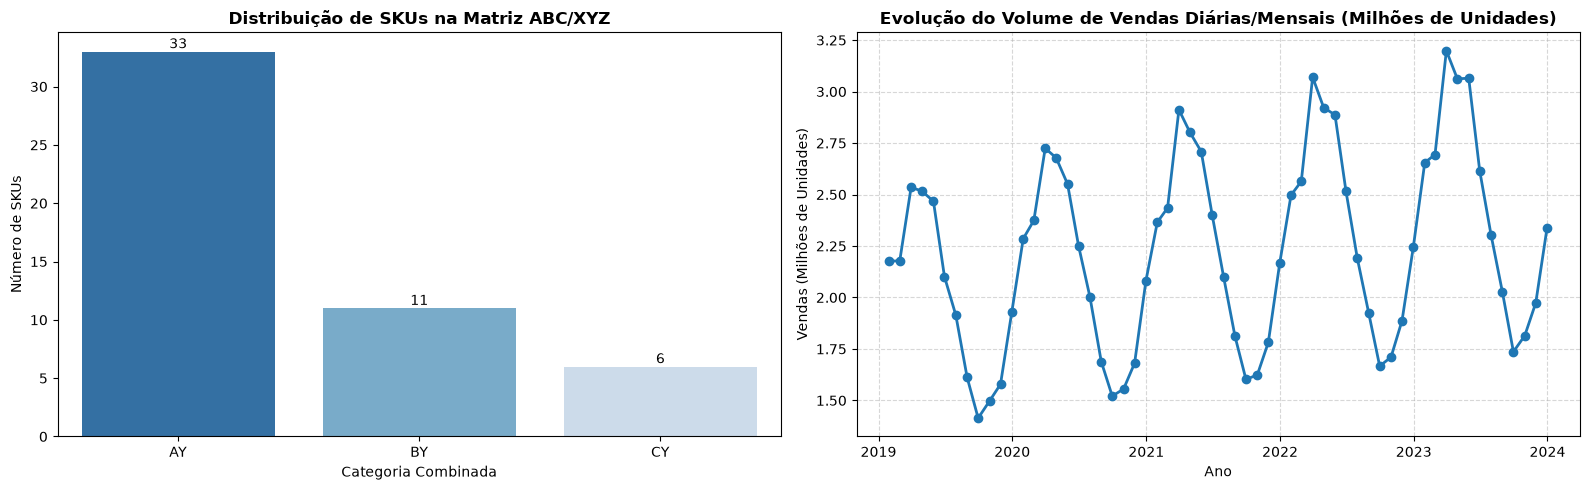

In [5]:
# Célula 4: Visualização Executiva da Matriz e Evolução Temporal
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Gráfico de barras da Matriz ABC/XYZ
abc_xyz_counts = item_stats['matriz_abc_xyz'].value_counts().reset_index()
abc_xyz_counts.columns = ['Categoria', 'Quantidade']

sns.barplot(data=abc_xyz_counts, x='Categoria', y='Quantidade', hue='Categoria', palette='Blues_r', ax=axes[0], legend=False)
axes[0].set_title('Distribuição de SKUs na Matriz ABC/XYZ', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Número de SKUs')
axes[0].set_xlabel('Categoria Combinada')

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# 2. Série Temporal Global Mensal (Tendência e Sazonalidade)
monthly_sales = df.groupby(pd.Grouper(key='date', freq='ME'))['sales'].sum().reset_index()

axes[1].plot(monthly_sales['date'], monthly_sales['sales'] / 1e6, color='#1f77b4', linewidth=2, marker='o')
axes[1].set_title('Evolução do Volume de Vendas Diárias/Mensais (Milhões de Unidades)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Vendas (Milhões de Unidades)')
axes[1].set_xlabel('Ano')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()